# Wykład 02 — eksperyment: perceptron, MLP i funkcje aktywacji

Materiał towarzyszący [`lecture.md`](lecture.md). Pokazujemy: (1) pojedynczy
perceptron zawodzi na XOR, (2) ręcznie skonstruowany MLP rozwiązuje XOR bez
treningu, (3) funkcje aktywacji i ich pochodne, (4)–(5) model liniowy kontra
MLP na danych nieliniowo separowalnych, (6) co się dzieje, gdy usuniemy
nieliniowość.


In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")


Używane urządzenie: cpu


## 1. Problem XOR i pojedynczy perceptron

Cztery punkty, etykieta to XOR współrzędnych. Trenujemy pojedynczą warstwę
liniową (`nn.Linear(2, 1)`) jako klasyfikator — to jest dokładnie perceptron
z sekcji *Formalny model*, tylko trenowany gradientowo zamiast klasyczną
regułą Rosenblatta (bo nasza warstwa liczy stratę z logitu, różniczkowalną).


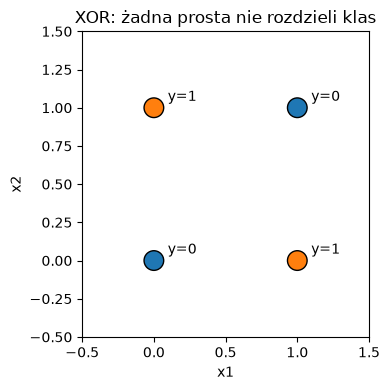

In [2]:
X_xor = torch.tensor([[0., 0.], [1., 0.], [0., 1.], [1., 1.]], device=device)
y_xor = torch.tensor([0., 1., 1., 0.], device=device)

plt.figure(figsize=(4, 4))
colors = ["tab:blue" if label == 0 else "tab:orange" for label in y_xor.cpu()]
plt.scatter(X_xor[:, 0].cpu(), X_xor[:, 1].cpu(), c=colors, s=200, edgecolor="black")
for (x1, x2), label in zip(X_xor.cpu().tolist(), y_xor.cpu().tolist()):
    plt.annotate(f"y={int(label)}", (x1, x2), textcoords="offset points", xytext=(10, 5))
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("XOR: żadna prosta nie rozdzieli klas")
plt.xlim(-0.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.tight_layout()
plt.show()


In [3]:
torch.manual_seed(0)
linear_xor = nn.Linear(2, 1).to(device)
optimizer = torch.optim.Adam(linear_xor.parameters(), lr=0.5)
loss_fn = nn.BCEWithLogitsLoss()

loss_history_xor = []
for epoch in range(500):
    optimizer.zero_grad()
    logits = linear_xor(X_xor).squeeze(-1)
    loss = loss_fn(logits, y_xor)
    loss.backward()
    optimizer.step()
    loss_history_xor.append(loss.item())

with torch.no_grad():
    probs = torch.sigmoid(linear_xor(X_xor).squeeze(-1))
    preds = (probs > 0.5).float()
    accuracy = (preds == y_xor).float().mean().item()
    final_weight = linear_xor.weight.detach().clone()
    final_bias = linear_xor.bias.detach().clone()

ln2 = torch.log(torch.tensor(2.0)).item()
print(f"Strata koncowa: {loss_history_xor[-1]:.4f}  (ln(2) = {ln2:.4f} = losowe zgadywanie)")
print(f"Prawdopodobienstwa: {[round(p, 3) for p in probs.tolist()]}")
print(f"Wagi: {final_weight.tolist()}  bias: {final_bias.tolist()}")
print(f"Dokladnosc (prog 0.5): {accuracy:.2f}  (cel: {y_xor.tolist()})")


Strata koncowa: 0.6931  (ln(2) = 0.6931 = losowe zgadywanie)
Prawdopodobienstwa: [0.5, 0.5, 0.5, 0.5]
Wagi: [[1.6707917893654667e-07, 6.381922901255166e-08]]  bias: [8.245521598837513e-08]
Dokladnosc (prog 0.5): 0.75  (cel: [0.0, 1.0, 1.0, 0.0])


Strata utyka dokładnie na poziomie $\ln 2 \approx 0{,}69$ — stracie
losowego zgadywania przy dwóch równolicznych klasach — **niezależnie od
ziarna losowości**. Co ciekawe, wagi i bias zbiegają w okolice zera, więc
model przewiduje prawdopodobieństwo $\approx 0{,}5$ dla *każdego* punktu:
przez symetrię XOR (poprawienie predykcji dla jednego punktu pogarsza ją
dla innego o dokładnie tyle samo) najlepsze, co może zrobić optymalizator,
to "poddać się" i nie faworyzować żadnej klasy. W tym reżimie **dokładność
licząca się z progu 0,5 jest artefaktem szumu numerycznego** wokół $0{,}5$
(zmienia się między uruchomieniami z różnym ziarnem — sprawdzaliśmy to) —
to sama strata, nie accuracy, jest tu wiarygodnym sygnałem, że model
niczego się nie nauczył.


## 2. Ręcznie skonstruowany MLP rozwiązuje XOR

Te same wagi, co w przykładzie rozwiązanym na wykładzie — bez treningu.


In [4]:
manual_mlp = nn.Sequential(
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1),
).to(device)

with torch.no_grad():
    manual_mlp[0].weight.copy_(torch.tensor([[1., 1.], [1., 1.]]))
    manual_mlp[0].bias.copy_(torch.tensor([0., -1.]))
    manual_mlp[2].weight.copy_(torch.tensor([[1., -2.]]))
    manual_mlp[2].bias.copy_(torch.tensor([0.]))

with torch.no_grad():
    manual_out = manual_mlp(X_xor).squeeze(-1)

print(f"Wyjscie MLP:  {manual_out.tolist()}")
print(f"Cel:          {y_xor.tolist()}")
assert torch.allclose(manual_out, y_xor, atol=1e-6)
print("OK: rece skonstruowany MLP trafia XOR dokladnie, bez treningu.")


Wyjscie MLP:  [0.0, 1.0, 1.0, 0.0]
Cel:          [0.0, 1.0, 1.0, 0.0]
OK: rece skonstruowany MLP trafia XOR dokladnie, bez treningu.


## 3. Funkcje aktywacji: wykresy i pochodne

Pochodną liczymy dwoma sposobami — ze wzoru w zamkniętej postaci i przez
`autograd` — tak jak w wykładzie 1 weryfikowaliśmy gradient MSE.


In [5]:
z = torch.linspace(-5, 5, 200)

def sigmoid(z):
    return 1 / (1 + torch.exp(-z))

def sigmoid_grad_formula(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh_grad_formula(z):
    return 1 - torch.tanh(z) ** 2

def relu_grad_formula(z):
    return (z > 0).float()

activations = {
    "sigmoid": (sigmoid, sigmoid_grad_formula),
    "tanh": (torch.tanh, tanh_grad_formula),
    "ReLU": (torch.relu, relu_grad_formula),
}

autograd_grads = {}
for name, (fn, _) in activations.items():
    z_ag = z.clone().requires_grad_(True)
    out = fn(z_ag)
    out.sum().backward()
    autograd_grads[name] = z_ag.grad.clone()

for name, (fn, grad_formula) in activations.items():
    formula_grad = grad_formula(z)
    max_diff = (formula_grad - autograd_grads[name]).abs().max().item()
    print(f"{name:8s} max|wzor - autograd| = {max_diff:.2e}")
    assert torch.allclose(formula_grad, autograd_grads[name], atol=1e-5)
print("OK: pochodne ze wzoru i z autograd sie zgadzaja.")


sigmoid  max|wzor - autograd| = 7.82e-08
tanh     max|wzor - autograd| = 0.00e+00
ReLU     max|wzor - autograd| = 0.00e+00
OK: pochodne ze wzoru i z autograd sie zgadzaja.


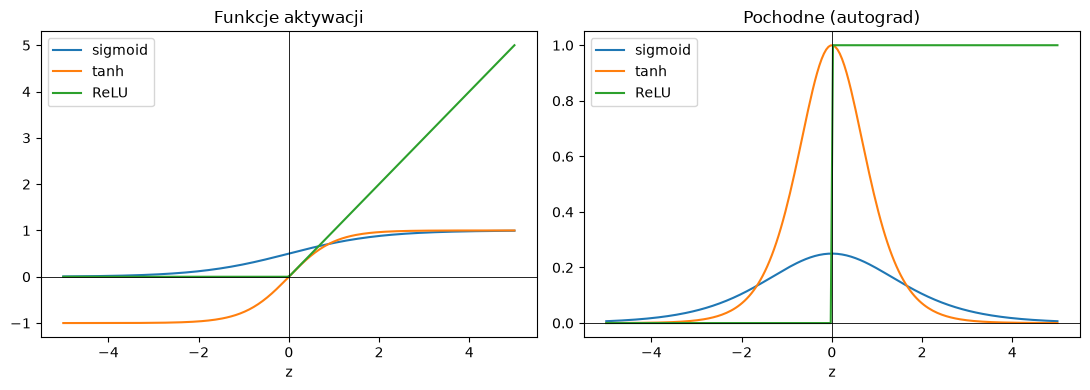

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, (fn, _) in activations.items():
    axes[0].plot(z, fn(z), label=name)
axes[0].axhline(0, color="black", linewidth=0.6)
axes[0].axvline(0, color="black", linewidth=0.6)
axes[0].set_title("Funkcje aktywacji")
axes[0].set_xlabel("z")
axes[0].legend()

for name in activations:
    axes[1].plot(z, autograd_grads[name], label=name)
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].axvline(0, color="black", linewidth=0.6)
axes[1].set_title("Pochodne (autograd)")
axes[1].set_xlabel("z")
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Dane: dwa przeplatające się półksiężyce

Generujemy je parametrycznie (bez pobierania czegokolwiek, bez nowych
zależności) i dzielimy na zbiór treningowy/testowy.


N_train=240, N_test=60


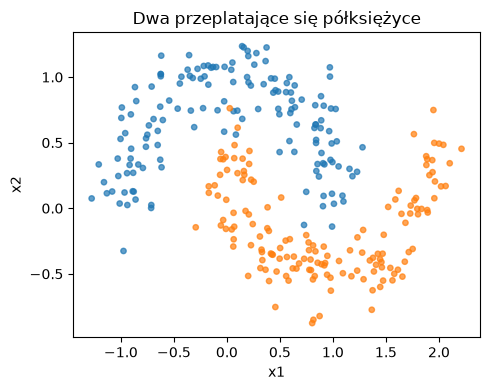

In [7]:
def make_moons(n_samples, noise, seed):
    g = torch.Generator().manual_seed(seed)
    n0 = n_samples // 2
    n1 = n_samples - n0

    theta0 = torch.pi * torch.rand(n0, generator=g)
    moon0 = torch.stack([torch.cos(theta0), torch.sin(theta0)], dim=1)

    theta1 = torch.pi * torch.rand(n1, generator=g)
    moon1 = torch.stack([1 - torch.cos(theta1), 1 - torch.sin(theta1) - 0.5], dim=1)

    X = torch.cat([moon0, moon1], dim=0)
    y = torch.cat([torch.zeros(n0), torch.ones(n1)])
    X = X + noise * torch.randn(X.shape[0], 2, generator=g)

    perm = torch.randperm(X.shape[0], generator=g)
    return X[perm], y[perm]


X, y = make_moons(n_samples=300, noise=0.15, seed=0)

n = X.shape[0]
perm = torch.randperm(n)
n_test = int(0.2 * n)
test_idx, train_idx = perm[:n_test], perm[n_test:]

X_train, y_train = X[train_idx].to(device), y[train_idx].to(device)
X_test, y_test = X[test_idx].to(device), y[test_idx].to(device)

print(f"N_train={len(train_idx)}, N_test={len(test_idx)}")

colors_moons = ["tab:blue" if v == 0 else "tab:orange" for v in y]
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=colors_moons, s=15, alpha=0.7)
plt.title("Dwa przeplatające się półksiężyce")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()
plt.show()


## 5. Model liniowy kontra MLP: trening i granice decyzyjne

`nn.Linear(2, 1)` to dokładnie $z = Wx+b$. Dla MLP wstawiamy `nn.ReLU()`
między dwie takie warstwy. `optimizer.step()` wykonuje tę samą aktualizację
parametrów, którą w wykładzie 1 pisaliśmy ręcznie jako `w -= lr * w.grad` —
tutaj deleguje to do `torch.optim.Adam` jako narzędzia (mechanizm
optymalizatorów to wykład 4).


In [8]:
def build_model(hidden=None, activation="relu"):
    if hidden is None:
        return nn.Linear(2, 1)
    act_layer = {"relu": nn.ReLU, "identity": nn.Identity}[activation]
    return nn.Sequential(
        nn.Linear(2, hidden),
        act_layer(),
        nn.Linear(hidden, 1),
    )


def train_classifier(model, X_train, y_train, epochs=500, lr=0.1, seed=0):
    torch.manual_seed(seed)
    model = model.to(X_train.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    loss_history = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        logits = model(X_train).squeeze(-1)
        loss = loss_fn(logits, y_train)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    return model, loss_history


def accuracy(model, X, y):
    with torch.no_grad():
        preds = (torch.sigmoid(model(X).squeeze(-1)) > 0.5).float()
        return (preds == y).float().mean().item()


def report(name, model, loss):
    train_acc = accuracy(model, X_train, y_train)
    test_acc = accuracy(model, X_test, y_test)
    print(f"{name:14s} loss={loss:.4f}  train_acc={train_acc:.3f}  test_acc={test_acc:.3f}")


linear_model, linear_loss_hist = train_classifier(build_model(), X_train, y_train)
mlp_model, mlp_loss_hist = train_classifier(
    build_model(hidden=16, activation="relu"), X_train, y_train
)

report("Liniowy", linear_model, linear_loss_hist[-1])
report("MLP (ReLU)", mlp_model, mlp_loss_hist[-1])


Liniowy        loss=0.2817  train_acc=0.863  test_acc=0.883
MLP (ReLU)     loss=0.0125  train_acc=0.996  test_acc=0.967


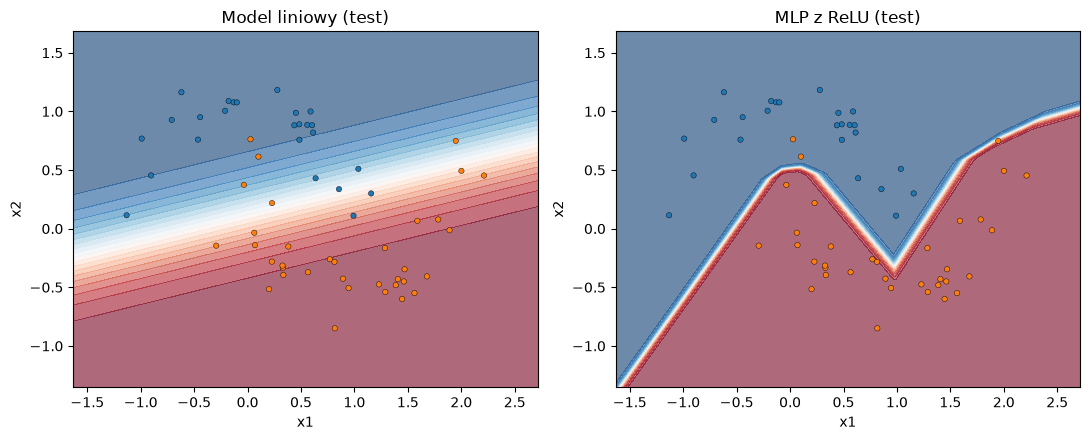

In [9]:
def plot_decision_boundary(ax, model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = torch.meshgrid(
        torch.linspace(x_min, x_max, 200),
        torch.linspace(y_min, y_max, 200),
        indexing="xy",
    )
    grid = torch.stack([xx.reshape(-1), yy.reshape(-1)], dim=1).to(X.device)
    with torch.no_grad():
        probs = torch.sigmoid(model(grid).squeeze(-1)).cpu().reshape(xx.shape)

    ax.contourf(xx.cpu(), yy.cpu(), probs, levels=20, cmap="RdBu_r", alpha=0.6, vmin=0, vmax=1)
    ax.scatter(
        X[:, 0].cpu(), X[:, 1].cpu(),
        c=["tab:blue" if v == 0 else "tab:orange" for v in y.cpu()],
        s=15, edgecolor="black", linewidth=0.3,
    )
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_decision_boundary(axes[0], linear_model, X_test, y_test, "Model liniowy (test)")
plot_decision_boundary(axes[1], mlp_model, X_test, y_test, "MLP z ReLU (test)")
plt.tight_layout()
plt.show()


## 6. Ablacja: co się dzieje bez nieliniowości?

Dokładnie ta sama architektura co MLP powyżej (dwie warstwy `nn.Linear`),
ale z `nn.Identity()` zamiast `nn.ReLU()` między nimi.


Liniowy        loss=0.2817  train_acc=0.863  test_acc=0.883
MLP bez aktyw. loss=0.2817  train_acc=0.863  test_acc=0.883
MLP (ReLU)     loss=0.0125  train_acc=0.996  test_acc=0.967


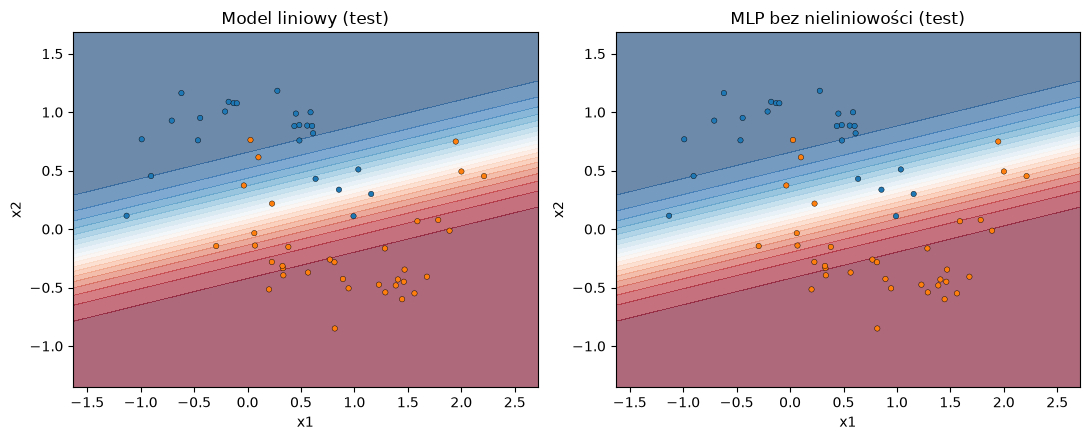

In [10]:
noact_model, noact_loss_hist = train_classifier(
    build_model(hidden=16, activation="identity"), X_train, y_train
)

report("Liniowy", linear_model, linear_loss_hist[-1])
report("MLP bez aktyw.", noact_model, noact_loss_hist[-1])
report("MLP (ReLU)", mlp_model, mlp_loss_hist[-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
plot_decision_boundary(axes[0], linear_model, X_test, y_test, "Model liniowy (test)")
plot_decision_boundary(axes[1], noact_model, X_test, y_test, "MLP bez nieliniowości (test)")
plt.tight_layout()
plt.show()


## Podsumowanie

- Pojedynczy perceptron utyka na XOR na poziomie losowego zgadywania;
  ręcznie skonstruowany MLP z ReLU trafia idealnie, bez treningu.
- Pochodne sigmoid/tanh/ReLU z `autograd` zgadzają się ze wzorami w
  zamkniętej postaci.
- Na półksiężycach MLP z ReLU wyraźnie bije model liniowy na zbiorze
  testowym; MLP **bez** nieliniowości osiąga (w granicach losowości
  optymalizacji) tę samą stratę i dokładność co model czysto liniowy —
  empiryczne potwierdzenie dowodu o kompozycji przekształceń afinicznych.

Pytania do dyskusji i bibliografia: zobacz [`lecture.md`](lecture.md).
